In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

POLL = ["PM2.5", "NO", "NO2", "NOx", "NH3", "CO", "SO2"]   # pollutants that exist at this station
day = pd.read_csv("../data/raw/station_day.csv", parse_dates=["Date"])
m = day[day["StationId"] == "TN003"].set_index("Date").sort_index()
m = m[["AQI", "AQI_Bucket"] + POLL]
full = pd.date_range(m.index.min(), m.index.max(), freq="D")
m = m.reindex(full)                       # one row per calendar day; missing days become NaN
m.index.name = "Date"
print(m.shape, m.index.min().date(), "to", m.index.max().date())
print("AQI missing:", m["AQI"].isna().sum(), "of", len(m))

(2009, 9) 2015-01-01 to 2020-07-01
AQI missing: 590 of 2009


In [2]:
miss = m["AQI"].isna()
run_id = (miss != miss.shift()).cumsum()
gaps = (miss.groupby(run_id).agg(["first", "size"]).rename(columns={"first": "is_gap", "size": "days"}))
starts = m.index.to_series().groupby(run_id).first()
gaps["start"] = starts
gaps = gaps[gaps["is_gap"]]
print("Gap length distribution (days):")
print(gaps["days"].describe().round(1))
print("\nGaps longer than 5 days:")
display(gaps[gaps["days"] > 5].sort_values("days", ascending=False))

Gap length distribution (days):
count     35.0
mean      16.9
std       70.0
min        1.0
25%        1.0
50%        1.0
75%        2.5
max      411.0
Name: days, dtype: float64

Gaps longer than 5 days:


,is_gap,days,start
AQI,,,
21,True,411,2016-08-13
1,True,82,2015-01-01
63,True,25,2019-11-10
13,True,11,2016-06-04
43,True,10,2019-08-23
35,True,7,2019-05-17


In [4]:
MAXFILL = 5
a = m["AQI"].interpolate(method="linear", limit=MAXFILL, limit_area="inside")
ok = a.notna()
seg_id = (ok != ok.shift()).cumsum()
dates = a.index.to_series()

segs = pd.DataFrame({
    "start": dates[ok].groupby(seg_id[ok]).min(),
    "end":   dates[ok].groupby(seg_id[ok]).max(),
    "days":  dates[ok].groupby(seg_id[ok]).size(),
}).sort_values("days", ascending=False)

print("Longest continuous AQI stretches after filling gaps of <=", MAXFILL, "days:")
display(segs.head(5))

Longest continuous AQI stretches after filling gaps of <= 5 days:


,start,end,days
AQI,,,
6,2017-09-28,2019-05-21,601
2,2015-03-24,2016-06-08,443
12,2019-12-05,2020-07-01,210
8,2019-05-24,2019-08-27,96
10,2019-09-02,2019-11-14,74


In [5]:
best = segs.iloc[0]
start, end = best["start"], best["end"]
c = m.loc[start:end].copy()
c["AQI_filled"] = c["AQI"].isna() & a.loc[start:end].notna()   # True = value came from interpolation
c["AQI"] = a.loc[start:end]
for p in POLL:                                                   # same rule for the pollutants
    c[p] = c[p].interpolate(method="linear", limit=MAXFILL, limit_area="inside")
print("Dataset:", start.date(), "to", end.date(), "|", len(c), "days")
print("AQI values filled by interpolation:", int(c["AQI_filled"].sum()))
print("\nPollutant missing % in this stretch:")
print((100 * c[POLL].isna().mean()).round(1))

Dataset: 2017-09-28 to 2019-05-21 | 601 days
AQI values filled by interpolation: 15

Pollutant missing % in this stretch:
PM2.5    0.8
NO       0.8
NO2      0.8
NOx      1.8
NH3      0.8
CO       0.8
SO2      0.8
dtype: float64


In [6]:
print(c["AQI"].describe().round(1))
print("\nDays with AQI above 500 (top of the official scale):", int((c["AQI"] > 500).sum()))
print("Days with AQI of 0 or below:", int((c["AQI"] <= 0).sum()))
for p in POLL:
    print(f"{p}: min {c[p].min():.1f}, median {c[p].median():.1f}, max {c[p].max():.1f}")

count    601.0
mean     122.7
std       68.6
min       34.0
25%       74.0
50%       94.0
75%      157.0
max      482.0
Name: AQI, dtype: float64

Days with AQI above 500 (top of the official scale): 0
Days with AQI of 0 or below: 0
PM2.5: min 5.3, median 52.3, max 311.4
NO: min 1.8, median 10.6, max 183.4
NO2: min 5.5, median 19.2, max 159.2
NOx: min 0.0, median 21.0, max 184.5
NH3: min 1.3, median 58.2, max 328.9
CO: min 0.0, median 0.9, max 40.2
SO2: min 1.1, median 9.5, max 87.8


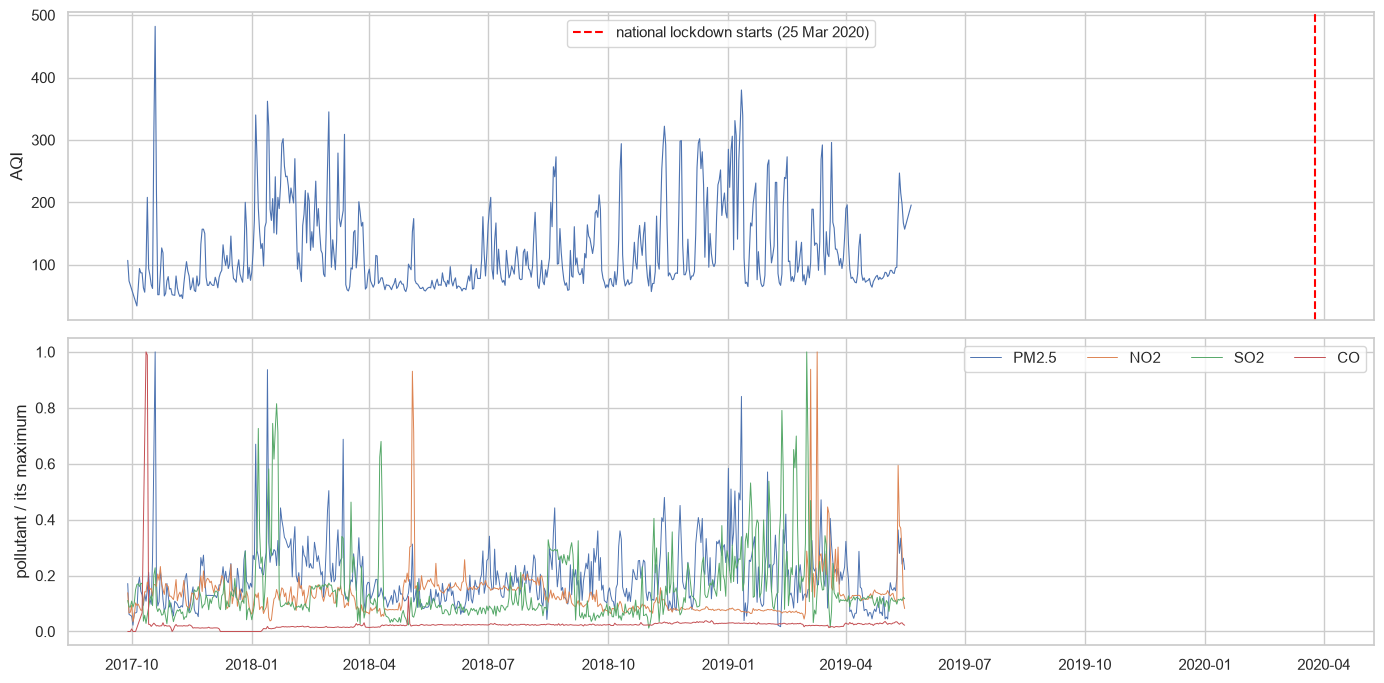

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(c.index, c["AQI"], lw=0.8)
axes[0].axvline(pd.Timestamp("2020-03-25"), color="red", ls="--", label="national lockdown starts (25 Mar 2020)")
axes[0].set_ylabel("AQI"); axes[0].legend()
for p in ["PM2.5", "NO2", "SO2", "CO"]:
    axes[1].plot(c.index, c[p] / c[p].max(), lw=0.7, label=p)
axes[1].set_ylabel("pollutant / its maximum"); axes[1].legend(ncol=4)
plt.tight_layout(); plt.savefig("../figures/02_clean_series.png", dpi=150); plt.show()

In [8]:
c.to_csv("../data/processed/manali_daily.csv")
print("Saved", c.shape)

Saved (601, 10)
